# Question 2 — Motion or Memory?
Hasan Amjad (25280042)

In [3]:
%load_ext autoreload
%autoreload 2
import platform, time, torch
from q2.common import *
from q2.transforms import *
from q2.models import *

DEVICE = get_device()
print("torch", torch.__version__, "| device:", DEVICE, "|", platform.platform(), platform.processor())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
torch 2.15.0 | device: mps | macOS-27.0.1-arm64-arm-64bit arm


## 1. Setup
### Table 1 — checks

In [4]:
from q2.checks import run_table1, print_table1
table1 = run_table1()
print_table1(table1)
save_json(table1, "table1.json");

    Check                                      Expected                                Yours
(a) max|M(M(x)) - x|                           0                                       0 (torch.equal: True)  [OK ]
(b) max|R^4(x) - x|                            0                                       0 (torch.equal: True)  [OK ]
(c) max|M R M(x) - R^-1(x)|                    0                                       0 (torch.equal: True)  [OK ]
(d) bright pixel of M(p) (frame, row, column)  (7, 10, 43)                             (7, 10, 43)  [OK ]
(e) bright pixel of R(p) (frame, row, column)  (7, 43, 10)                             (7, 43, 10)  [OK ]
(f) 1x input / target frames                   1, 2, 3, 4, 5 / 6, 7, 8, 9, 10          1, 2, 3, 4, 5 / 6, 7, 8, 9, 10  [OK ]
(g) 2x input / target frames                   1, 3, 5, 7, 9 / 11, 13, 15, 17, 19      1, 3, 5, 7, 9 / 11, 13, 15, 17, 19  [OK ]
(h) 3x input / target frames                   1, 4, 7, 10, 13 / 16, 19                1, 4, 

### Data

In [5]:
data = load_moving_mnist()
train_u8, val_u8, test_u8 = splits(data)
print("all", tuple(data.shape), data.dtype, "| train", len(train_u8), "| val", len(val_u8), "| test", len(test_u8))

all (10000, 20, 1, 64, 64) torch.uint8 | train 8000 | val 1000 | test 1000


### Figure 1 — training-data motion

pairs = 950, pixels kept = 103,050, median speed = 3.32 px/frame
2x -> 6.635 px/frame;  3x -> 9.953 px/frame
direction fractions per 20-degree bin: [0.049, 0.0488, 0.0675, 0.0731, 0.0602, 0.0561, 0.0263, 0.0326, 0.0384, 0.082, 0.0642, 0.0541, 0.0666, 0.0614, 0.0571, 0.0366, 0.0487, 0.0772]


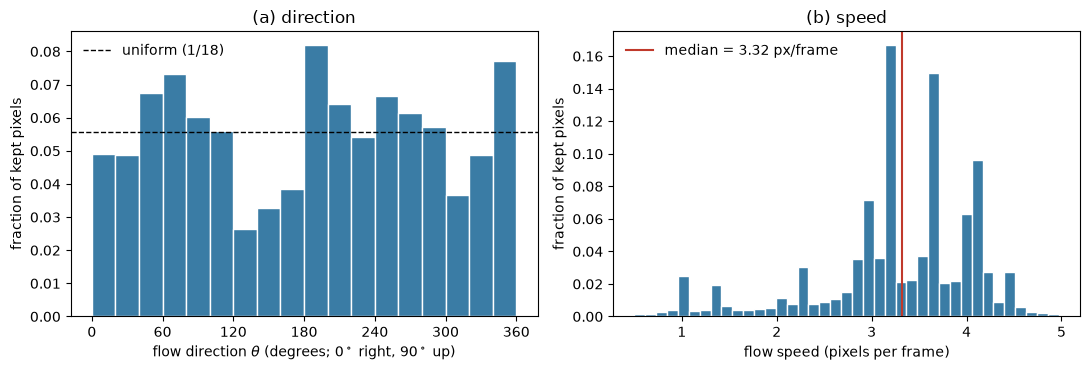

In [6]:
from q2.flow import pooled_flow, figure1
dx, dy, n_pairs = pooled_flow(train_u8, n_videos=50)
fig, fig1_stats = figure1(dx, dy, FIG_DIR / "fig1_flow_stats.png")
fig1_stats["n_pairs"] = n_pairs
save_json(fig1_stats, "fig1_stats.json")
print(f"pairs = {n_pairs}, pixels kept = {fig1_stats['n_pixels']:,}, median speed = {fig1_stats['median_speed']:.3g} px/frame")
print("2x ->", round(2*fig1_stats['median_speed'], 3), "px/frame;  3x ->", round(3*fig1_stats['median_speed'], 3), "px/frame")
print("direction fractions per 20-degree bin:", fig1_stats["direction_fractions"])

### Model A — parameter count

In [7]:
mA = model_A()
print("model A params:", n_params(mA))
assert n_params(mA) == 480_784
with torch.no_grad():
    out = mA(torch.rand(2, 5, 1, 64, 64))
print("output shape:", tuple(out.shape))

model A params: 480784
output shape: (2, 5, 1, 64, 64)
